# Bài tập Lab 7: Đánh giá mô hình


## Chuẩn bị
Chạy ô này trước, sau đó chạy các cell theo thứ tự. Nếu CSV ở nơi khác, điền đường dẫn vào các biến `DUONG_DAN_...`. Khi dùng Colab, tải CSV lên theo lời nhắc.

In [1]:
import os
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Có thể chỉ định CSV ở ngoài data; để trống để tự tìm.
DUONG_DAN_SINH_VIEN = os.environ.get("LAB7_SINH_VIEN", "")
DUONG_DAN_GIA_NHA = os.environ.get("LAB7_GIA_NHA", "")

def tim_dataset(ten_tep, duong_dan_chi_dinh=""):
    if duong_dan_chi_dinh:
        tep = Path(duong_dan_chi_dinh).expanduser()
        if not tep.is_file():
            raise FileNotFoundError(f"Khong tim thay dataset: {tep.name}")
        return tep.resolve()
    hien_tai = Path.cwd().resolve()
    cac_goc = [hien_tai, hien_tai.parent, hien_tai.parent.parent]
    if os.environ.get("LAB7_ROOT"):
        cac_goc.insert(0, Path(os.environ["LAB7_ROOT"]))
    for goc in cac_goc:
        for tep in [goc / "07. Accuracy_Metrics" / "data" / ten_tep,
                    goc / "data" / ten_tep, goc / ten_tep,
                    goc / "07. Accuracy_Metrics" / ten_tep]:
            if tep.is_file():
                return tep.resolve()
    if "google.colab" in sys.modules:
        from google.colab import files
        print(f"Hay tai len {ten_tep}; co the chon ca hai CSV cung luc.")
        files.upload()
        if (hien_tai / ten_tep).is_file():
            return (hien_tai / ten_tep).resolve()
    raise FileNotFoundError(f"Can tep {ten_tep}. Hay chi dinh duong dan trong o Chuan bi.")

def doc_dataset(ten_tep, duong_dan_chi_dinh, cac_cot):
    tep = tim_dataset(ten_tep, duong_dan_chi_dinh)
    bang = pd.read_csv(tep)
    if not set(cac_cot).issubset(bang.columns):
        raise ValueError(f"{ten_tep} can cac cot: {', '.join(cac_cot)}")
    bang = bang[cac_cot].apply(pd.to_numeric, errors="coerce")
    if len(bang) == 0 or not np.isfinite(bang.to_numpy(dtype=float)).all():
        raise ValueError(f"{ten_tep} rong hoac co gia tri thieu/khong phai so huu han.")
    print("Dataset dang su dung:", tep.name)
    return bang

thu_muc_lab = Path(os.environ.get("LAB7_ROOT", Path.cwd())).resolve()
if "LAB7_ROOT" not in os.environ:
    if thu_muc_lab.name == "code":
        thu_muc_lab = thu_muc_lab.parent
    elif (thu_muc_lab / "07. Accuracy_Metrics").is_dir():
        thu_muc_lab = thu_muc_lab / "07. Accuracy_Metrics"
thu_muc_hinh = thu_muc_lab / "figures"
thu_muc_hinh.mkdir(parents=True, exist_ok=True)

# Giữ cảnh báo của thư viện nhưng không in đường dẫn cài đặt Python cá nhân.
def in_canh_bao_ngan(message, category, filename, lineno, file=None, line=None):
    noi_dung = str(message)
    for thu_muc in [thu_muc_lab, Path.home()]:
        for dang_duong_dan in [str(thu_muc), thu_muc.as_posix()]:
            noi_dung = noi_dung.replace(dang_duong_dan, "<thu_muc>")
    print(f"Canh bao {category.__name__}: {noi_dung}", file=file or sys.stdout)

warnings.showwarning = in_canh_bao_ngan

from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

du_lieu_bo_hoc = doc_dataset("sinh_vien_bo_hoc.csv", DUONG_DAN_SINH_VIEN,
    ["diem_tb", "so_buoi_vang", "tin_chi_no", "gio_lam_them", "bo_hoc"])
if set(du_lieu_bo_hoc["bo_hoc"].unique()) != {0, 1}:
    raise ValueError("Nhan bo_hoc phai gom hai lop 0 va 1.")
du_lieu_bo_hoc["bo_hoc"] = du_lieu_bo_hoc["bo_hoc"].astype(int)
du_lieu_nha = doc_dataset("gia_nha.csv", DUONG_DAN_GIA_NHA,
    ["dien_tich", "so_phong", "tuoi_nha", "gia"])

def chia_du_lieu_bo_hoc():
    return train_test_split(du_lieu_bo_hoc.drop(columns="bo_hoc"),
        du_lieu_bo_hoc["bo_hoc"], test_size=0.25, random_state=17,
        stratify=du_lieu_bo_hoc["bo_hoc"])

def tao_logistic():
    return make_pipeline(StandardScaler(), LogisticRegression())


Dataset dang su dung: sinh_vien_bo_hoc.csv
Dataset dang su dung: gia_nha.csv


## Bài 1: Tự viết hàm đánh giá
Chỉ dùng NumPy trong `danh_gia`; đối chiếu logistic và mô hình lười với scikit-learn.

In [2]:
def danh_gia(y_that, y_doan):
    """Đánh giá nhị phân, lớp dương là 1; quy ước mẫu số 0 trả về 0."""
    nhan_that = np.asarray(y_that)
    nhan_doan = np.asarray(y_doan)
    if nhan_that.ndim != 1 or nhan_doan.ndim != 1 or nhan_that.shape != nhan_doan.shape:
        raise ValueError("Hai mang nhan phai mot chieu va cung kich thuoc.")
    if nhan_that.size == 0:
        raise ValueError("Khong the danh gia mang nhan rong.")
    if not (np.isin(nhan_that, [0, 1]).all() and np.isin(nhan_doan, [0, 1]).all()):
        raise ValueError("Ham chi nhan nhan nhi phan 0 va 1.")
    dung_duong = np.sum((nhan_that == 1) & (nhan_doan == 1))  # TP
    sai_duong = np.sum((nhan_that == 0) & (nhan_doan == 1))   # FP
    sot_duong = np.sum((nhan_that == 1) & (nhan_doan == 0))   # FN
    dung_am = np.sum((nhan_that == 0) & (nhan_doan == 0))     # TN
    accuracy = (dung_duong + dung_am) / nhan_that.size
    precision = dung_duong / (dung_duong + sai_duong) if dung_duong + sai_duong else 0.0
    recall = dung_duong / (dung_duong + sot_duong) if dung_duong + sot_duong else 0.0
    mau_so_f1 = 2 * dung_duong + sai_duong + sot_duong
    f1 = 2 * dung_duong / mau_so_f1 if mau_so_f1 else 0.0
    return {"accuracy": float(accuracy), "precision": float(precision),
            "recall": float(recall), "f1": float(f1)}

dac_trung_hoc, dac_trung_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_du_lieu_bo_hoc()
ket_qua_bai1 = {}
for ten, mo_hinh in [("Logistic", tao_logistic()),
                     ("Mo hinh luoi", DummyClassifier(strategy="most_frequent"))]:
    du_doan = mo_hinh.fit(dac_trung_hoc, nhan_hoc).predict(dac_trung_kiem_tra)
    tu_tinh = danh_gia(nhan_kiem_tra, du_doan)
    thu_vien = {"accuracy": accuracy_score(nhan_kiem_tra, du_doan),
        "precision": precision_score(nhan_kiem_tra, du_doan, zero_division=0),
        "recall": recall_score(nhan_kiem_tra, du_doan, zero_division=0),
        "f1": f1_score(nhan_kiem_tra, du_doan, zero_division=0)}
    nhan_that = nhan_kiem_tra.to_numpy()
    tp = int(np.sum((nhan_that == 1) & (du_doan == 1)))
    fp = int(np.sum((nhan_that == 0) & (du_doan == 1)))
    fn = int(np.sum((nhan_that == 1) & (du_doan == 0)))
    tn = int(np.sum((nhan_that == 0) & (du_doan == 0)))
    ket_qua_bai1[ten] = (tp, fp, fn, tn, tu_tinh)
    print(f"\n{ten}: TP={tp}, FP={fp}, FN={fn}, TN={tn}, tong={tp+fp+fn+tn}")
    print("Thuoc do      Tu tinh  Thu vien  Kiem tra")
    for thuoc_do in tu_tinh:
        khop = np.isclose(tu_tinh[thuoc_do], thu_vien[thuoc_do])
        print(f"{thuoc_do:10s}  {tu_tinh[thuoc_do]:.4f}   {thu_vien[thuoc_do]:.4f}    "
              + ("Khop" if khop else "Khong khop"))
        assert khop, "Ket qua tu tinh khong khop thu vien."

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
print("Lớp dương 1 là bỏ học. TP là báo bỏ học đúng; FP là báo nhầm người học tiếp; "
      "FN là bỏ sót người bỏ học; TN là nhận đúng người học tiếp. Trong ma trận thư viện, "
      "hàng là nhãn thật, cột là nhãn dự đoán, thứ tự trải phẳng là TN, FP, FN, TP.")
print("Accuracy = (TP + TN)/N; precision = TP/(TP + FP) cho biết bao nhiêu lời báo là đúng; "
      "recall = TP/(TP + FN) cho biết tìm được bao nhiêu người bỏ học thật. "
      "F1 = 2TP/(2TP + FP + FN), tương đương trung bình điều hòa của precision và recall.")
tp, fp, fn, tn, diem = ket_qua_bai1["Logistic"]
print(f"Logistic tìm được {tp}/{tp+fn} người bỏ học, báo nhầm {fp} người và bỏ sót {fn} người. "
      f"Accuracy {diem['accuracy']:.4f} vì vậy cần được đọc cùng recall {diem['recall']:.4f}.")
tp, fp, fn, tn, diem = ket_qua_bai1["Mo hinh luoi"]
print(f"Mô hình lười đạt accuracy {diem['accuracy']:.4f}, nhưng tìm được {tp} người bỏ học. "
      "Khi không dự đoán ai là lớp 1, TP + FP = 0 nên precision không xác định về mặt toán học. "
      "Hàm quy ước trả 0, khớp zero_division=0; điều này không có nghĩa phép chia 0/0 bằng 0.")
print("Hàm cũng trả recall = 0 nếu không có nhãn thật lớp 1, và F1 = 0 nếu mẫu số F1 bằng 0. "
      "Mảng rỗng bị từ chối vì không có mẫu để đánh giá. Quy ước được nêu rõ để tránh lỗi chia cho 0.")



Logistic: TP=17, FP=3, FN=13, TN=267, tong=300
Thuoc do      Tu tinh  Thu vien  Kiem tra
accuracy    0.9467   0.9467    Khop
precision   0.8500   0.8500    Khop
recall      0.5667   0.5667    Khop
f1          0.6800   0.6800    Khop

Mo hinh luoi: TP=0, FP=0, FN=30, TN=270, tong=300
Thuoc do      Tu tinh  Thu vien  Kiem tra
accuracy    0.9000   0.9000    Khop
precision   0.0000   0.0000    Khop
recall      0.0000   0.0000    Khop
f1          0.0000   0.0000    Khop

NHẬN XÉT VÀ GIẢI THÍCH
Lớp dương 1 là bỏ học. TP là báo bỏ học đúng; FP là báo nhầm người học tiếp; FN là bỏ sót người bỏ học; TN là nhận đúng người học tiếp. Trong ma trận thư viện, hàng là nhãn thật, cột là nhãn dự đoán, thứ tự trải phẳng là TN, FP, FN, TP.
Accuracy = (TP + TN)/N; precision = TP/(TP + FP) cho biết bao nhiêu lời báo là đúng; recall = TP/(TP + FN) cho biết tìm được bao nhiêu người bỏ học thật. F1 = 2TP/(2TP + FP + FN), tương đương trung bình điều hòa của precision và recall.
Logistic tìm được 17/30 người b

## Bài 2: Chữ số viết tay
Dùng lại SVM RBF chưa chuẩn hóa và cách chia dữ liệu của Lab 6.

In [3]:
anh_chu_so, nhan_chu_so = load_digits(return_X_y=True)
anh_hoc, anh_kiem_tra, so_hoc, so_kiem_tra = train_test_split(
    anh_chu_so, nhan_chu_so, test_size=0.25, random_state=17, stratify=nhan_chu_so)
svm_chu_so = SVC(kernel="rbf").fit(anh_hoc, so_hoc)
so_du_doan = svm_chu_so.predict(anh_kiem_tra)
print("Bao cao cho 10 chu so:")
print(classification_report(so_kiem_tra, so_du_doan, labels=np.arange(10),
    target_names=[str(so) for so in range(10)], digits=4, zero_division=0))
bao_cao = classification_report(so_kiem_tra, so_du_doan, labels=np.arange(10),
    output_dict=True, zero_division=0)
recall_tung_so = np.array([bao_cao[str(so)]["recall"] for so in range(10)])
precision_tung_so = np.array([bao_cao[str(so)]["precision"] for so in range(10)])
so_recall_thap = np.flatnonzero(np.isclose(recall_tung_so, recall_tung_so.min())).tolist()
so_precision_thap = np.flatnonzero(np.isclose(precision_tung_so, precision_tung_so.min())).tolist()
so_anh_moi_lop = np.bincount(so_kiem_tra, minlength=10)
print("Chu so co recall thap nhat:", so_recall_thap, f"({recall_tung_so.min():.4f})")
print("Chu so co precision thap nhat:", so_precision_thap, f"({precision_tung_so.min():.4f})")
print("So anh kiem tra moi chu so:", so_anh_moi_lop)
print("Chenh lech tuyet doi giua macro avg va weighted avg:")
for thuoc_do in ["precision", "recall", "f1-score"]:
    print(f"  {thuoc_do}: {abs(bao_cao['macro avg'][thuoc_do] - bao_cao['weighted avg'][thuoc_do]):.6f}")

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
print(f"Chữ số {so_recall_thap} có recall thấp nhất ({recall_tung_so.min():.4f}), "
      "nghĩa là có tỷ lệ ảnh thật thuộc chữ số đó bị nhận thành chữ số khác cao nhất.")
print(f"Chữ số {so_precision_thap} có precision thấp nhất ({precision_tung_so.min():.4f}), "
      "nghĩa là trong các ảnh bị mô hình gọi tên là chữ số đó, tỷ lệ gọi nhầm lớn nhất.")
print(f"Macro avg cho mỗi lớp trọng số 1/10; weighted avg dùng số ảnh thật của mỗi lớp làm trọng số. "
      f"Tập kiểm tra có từ {so_anh_moi_lop.min()} đến {so_anh_moi_lop.max()} ảnh mỗi chữ số, "
      "nên các trọng số gần nhau và hai cách trung bình gần bằng nhau. "
      "Sự gần nhau ở đây không phải là tính chất luôn đúng với dữ liệu lệch lớp.")


Bao cao cho 10 chu so:


              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Chu so co recall thap nhat: [8] (0.9767)
Chu so co precision thap nhat: [8] (0.9767)
So anh kiem tra moi chu so: [45 46 44 46 45 46 45 45 43 45]
Chenh lech tuyet doi giua macro avg va weighted avg:
  precision: 0.000009
  recall: 0.000103
 

## Bài 3: Chọn ngưỡng theo yêu cầu
Tìm ngưỡng lớn nhất có recall kiểm định chéo ít nhất 0,8. Chốt ngưỡng trước khi đánh giá tập kiểm tra.

In [4]:
dac_trung_hoc, dac_trung_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_du_lieu_bo_hoc()
logistic_nguong = tao_logistic()
xac_suat_ngoai_fold = cross_val_predict(logistic_nguong, dac_trung_hoc, nhan_hoc,
    cv=5, method="predict_proba")[:, 1]
nhan_hoc_mang = nhan_hoc.to_numpy()
muc_recall = 0.8
# Với quy tắc p >= ngưỡng, nhãn dự đoán chỉ đổi khi đi qua một xác suất quan sát.
# Xét tất cả các mốc để tìm ngưỡng lớn nhất, không giới hạn vào lưới bước 0.05.
cac_nguong = np.unique(np.r_[0.0, xac_suat_ngoai_fold, 1.0])
recall_ngoai_fold = np.array([
    np.sum((xac_suat_ngoai_fold >= nguong) & (nhan_hoc_mang == 1))
    / np.sum(nhan_hoc_mang == 1) for nguong in cac_nguong])
vi_tri_dat = np.flatnonzero(recall_ngoai_fold >= muc_recall)
vi_tri_chon = int(vi_tri_dat[-1])
nguong_chon = float(cac_nguong[vi_tri_chon])
du_doan_ngoai_fold = (xac_suat_ngoai_fold >= nguong_chon).astype(int)
print("Quy tac: bao bo hoc neu xac suat >= nguong")
print(f"So nguong da xet tren tap hoc: {len(cac_nguong)}")
print(f"Nguong lon nhat dat yeu cau: {nguong_chon:.12f}")
print(f"Recall ngoai fold: {recall_ngoai_fold[vi_tri_chon]:.4f}")
print(f"Precision ngoai fold: {precision_score(nhan_hoc, du_doan_ngoai_fold, zero_division=0):.4f}")
if vi_tri_chon + 1 < len(cac_nguong):
    print(f"Nguong ke tiep: {cac_nguong[vi_tri_chon+1]:.12f}; "
          f"recall: {recall_ngoai_fold[vi_tri_chon+1]:.4f}")

# Chỉ sau khi chọn xong ngưỡng mới fit toàn bộ tập học và mở tập kiểm tra một lần.
logistic_nguong.fit(dac_trung_hoc, nhan_hoc)
xac_suat_kiem_tra = logistic_nguong.predict_proba(dac_trung_kiem_tra)[:, 1]
du_doan_kiem_tra = (xac_suat_kiem_tra >= nguong_chon).astype(int)
recall_kiem_tra = recall_score(nhan_kiem_tra, du_doan_kiem_tra, zero_division=0)
precision_kiem_tra = precision_score(nhan_kiem_tra, du_doan_kiem_tra, zero_division=0)
so_ban_bi_bao = int(du_doan_kiem_tra.sum())
so_tim_dung = int(np.sum((du_doan_kiem_tra == 1) & (nhan_kiem_tra.to_numpy() == 1)))
print("\nKet qua tap kiem tra voi nguong da chot:")
print(f"Recall = {recall_kiem_tra:.4f}; " + ("Dat 0.8" if recall_kiem_tra >= muc_recall else "Chua dat 0.8"))
print(f"Precision = {precision_kiem_tra:.4f}")
print(f"So ban bi bao = {so_ban_bi_bao}; tim dung = {so_tim_dung}; bao nham = {so_ban_bi_bao-so_tim_dung}")

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
print("cross_val_predict chia riêng tập học thành 5 phần. Mỗi sinh viên được dự đoán bởi mô hình "
      "chưa học trên sinh viên đó. StandardScaler nằm trong pipeline nên cũng chỉ học thống kê "
      "từ phần huấn luyện của mỗi fold, tránh rò rỉ dữ liệu.")
print(f"Ngưỡng {nguong_chon:.12f} là mốc lớn nhất đạt recall ít nhất 0,8 trên các dự đoán ngoài fold. "
      "Khi tăng ngưỡng, tập người bị báo chỉ có thể thu hẹp, nên recall không thể tăng. "
      "Giữ ngưỡng cao nhất giúp hạn chế số lời báo trong khi vẫn đạt yêu cầu trên tập học; "
      "điều đó không bảo đảm precision là lớn nhất.")
print("Chương trình xét toàn bộ xác suất ngoài fold, vì vậy có thể chọn ngưỡng khác lưới 0,05 "
      "ở phần thực hành. Phép so sánh dùng giá trị đầy đủ, không dùng con số đã làm tròn khi in.")
print(f"Trên tập kiểm tra, recall = {recall_kiem_tra:.4f}, "
      + ("đạt" if recall_kiem_tra >= muc_recall else "chưa đạt")
      + f" yêu cầu 0,8; precision = {precision_kiem_tra:.4f} với {so_ban_bi_bao} người bị báo.")
print("Đạt 80% trên dự đoán ngoài fold không bảo đảm đạt 80% trên dữ liệu mới, vì mẫu kiểm tra "
      "và mô hình học toàn bộ tập học khác các fold. Sau khi đánh giá tập kiểm tra, không chỉnh lại "
      "ngưỡng theo nhãn kiểm tra; làm vậy sẽ dùng đáp án để lựa chọn và đánh giá thiếu khách quan.")


Quy tac: bao bo hoc neu xac suat >= nguong
So nguong da xet tren tap hoc: 899
Nguong lon nhat dat yeu cau: 0.171773644908
Recall ngoai fold: 0.8090
Precision ngoai fold: 0.5106
Nguong ke tiep: 0.171884149999; recall: 0.7978

Ket qua tap kiem tra voi nguong da chot:
Recall = 0.8000; Dat 0.8
Precision = 0.5106
So ban bi bao = 47; tim dung = 24; bao nham = 23

NHẬN XÉT VÀ GIẢI THÍCH
cross_val_predict chia riêng tập học thành 5 phần. Mỗi sinh viên được dự đoán bởi mô hình chưa học trên sinh viên đó. StandardScaler nằm trong pipeline nên cũng chỉ học thống kê từ phần huấn luyện của mỗi fold, tránh rò rỉ dữ liệu.
Ngưỡng 0.171773644908 là mốc lớn nhất đạt recall ít nhất 0,8 trên các dự đoán ngoài fold. Khi tăng ngưỡng, tập người bị báo chỉ có thể thu hẹp, nên recall không thể tăng. Giữ ngưỡng cao nhất giúp hạn chế số lời báo trong khi vẫn đạt yêu cầu trên tập học; điều đó không bảo đảm precision là lớn nhất.
Chương trình xét toàn bộ xác suất ngoài fold, vì vậy có thể chọn ngưỡng khác lưới 0,0

## Bài 4: Tự vẽ đường ROC
Vẽ logistic, rừng ngẫu nhiên và đường chéo trên cùng hình; lưu `figures/roc.png`.

Logistic: AUC = 0.9449


Rung ngau nhien: AUC = 0.9249
Da luu hinh: figures/roc.png


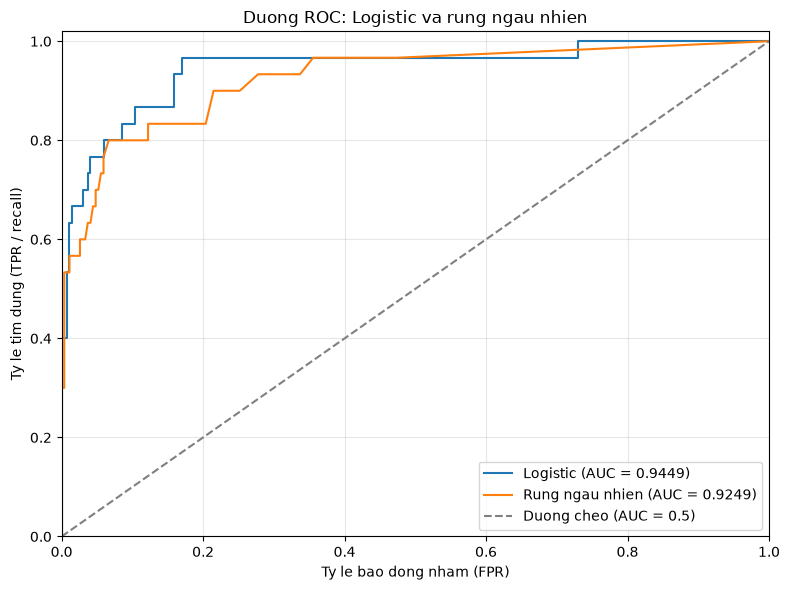


NHẬN XÉT VÀ GIẢI THÍCH
Logistic có AUC lớn hơn (0.9449), nghĩa là diện tích dưới đường ROC lớn hơn và khả năng xếp hạng tổng thể tốt hơn trên tập này.
Có vùng logistic cao hơn và có vùng rừng cao hơn, nên hai đường có giao nhau và đổi vị trí; không có một đường luôn ôm sát góc trên bên trái hơn ở mọi mức báo động nhầm.
Ví dụ Logistic cao hơn: FPR = 0.0000, TPR logistic = 0.4000, TPR rừng = 0.3000.
Ví dụ Rừng cao hơn: FPR = 0.0037, TPR logistic = 0.4000, TPR rừng = 0.5333.
Ở cùng FPR, TPR cao hơn nghĩa là tìm được nhiều người bỏ học hơn với cùng tỷ lệ báo nhầm. AUC lớn hơn không bảo đảm recall lớn hơn tại ngưỡng 0,5; chọn ngưỡng cần dựa trên tập học.


In [5]:
dac_trung_hoc, dac_trung_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_du_lieu_bo_hoc()
cac_mo_hinh_roc = {"Logistic": tao_logistic(),
    "Rung ngau nhien": RandomForestClassifier(n_estimators=200, random_state=0)}
duong_roc = {}
auc_cac_mo_hinh = {}
hinh, truc = plt.subplots(figsize=(8, 6))
for ten, mo_hinh in cac_mo_hinh_roc.items():
    xac_suat = mo_hinh.fit(dac_trung_hoc, nhan_hoc).predict_proba(dac_trung_kiem_tra)[:, 1]
    fpr, tpr, _ = roc_curve(nhan_kiem_tra, xac_suat)
    auc = roc_auc_score(nhan_kiem_tra, xac_suat)
    duong_roc[ten] = (fpr, tpr)
    auc_cac_mo_hinh[ten] = auc
    # Dùng plt.plot theo yêu cầu đề.
    plt.plot(fpr, tpr, label=f"{ten} (AUC = {auc:.4f})")
    print(f"{ten}: AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Duong cheo (AUC = 0.5)")
truc.set(xlabel="Ty le bao dong nham (FPR)", ylabel="Ty le tim dung (TPR / recall)",
         title="Duong ROC: Logistic va rung ngau nhien", xlim=(0, 1), ylim=(0, 1.02))
truc.legend(loc="lower right")
truc.grid(alpha=0.3)
hinh.tight_layout()
hinh.savefig(thu_muc_hinh / "roc.png", dpi=160, bbox_inches="tight")
print("Da luu hinh: figures/roc.png")
plt.show()
plt.close(hinh)

# So vị trí hai đường trên từng khoảng FPR, giữ cả hai phía của đoạn thẳng đứng.
# Không suy ra việc giao nhau chỉ từ AUC.
fpr_lr, tpr_lr = duong_roc["Logistic"]
fpr_rf, tpr_rf = duong_roc["Rung ngau nhien"]
moc_fpr = np.unique(np.r_[fpr_lr, fpr_rf])
so_sanh_vi_tri = []
for trai, phai in zip(moc_fpr[:-1], moc_fpr[1:]):
    giua = (trai + phai) / 2
    vi_tri_lr = np.searchsorted(fpr_lr, giua, side="right") - 1
    vi_tri_rf = np.searchsorted(fpr_rf, giua, side="right") - 1
    # Nội suy hai đầu và giữa mỗi khoảng, theo đúng các đoạn vẽ bởi plt.plot.
    for hoanh_do in [trai, giua, phai]:
        tung_do_lr = np.interp(hoanh_do, fpr_lr[vi_tri_lr:vi_tri_lr+2], tpr_lr[vi_tri_lr:vi_tri_lr+2])
        tung_do_rf = np.interp(hoanh_do, fpr_rf[vi_tri_rf:vi_tri_rf+2], tpr_rf[vi_tri_rf:vi_tri_rf+2])
        so_sanh_vi_tri.append((hoanh_do, tung_do_lr, tung_do_rf))
lr_cao_hon = [diem for diem in so_sanh_vi_tri if diem[1] > diem[2] + 1e-10]
rf_cao_hon = [diem for diem in so_sanh_vi_tri if diem[2] > diem[1] + 1e-10]

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
ten_auc_cao = max(auc_cac_mo_hinh, key=auc_cac_mo_hinh.get)
if np.isclose(auc_cac_mo_hinh["Logistic"], auc_cac_mo_hinh["Rung ngau nhien"]):
    print("Hai mô hình có AUC xấp xỉ bằng nhau trên tập kiểm tra này.")
else:
    print(f"{ten_auc_cao} có AUC lớn hơn ({auc_cac_mo_hinh[ten_auc_cao]:.4f}), "
          "nghĩa là diện tích dưới đường ROC lớn hơn và khả năng xếp hạng tổng thể tốt hơn trên tập này.")
if lr_cao_hon and rf_cao_hon:
    print("Có vùng logistic cao hơn và có vùng rừng cao hơn, nên hai đường có giao nhau và đổi vị trí; "
          "không có một đường luôn ôm sát góc trên bên trái hơn ở mọi mức báo động nhầm.")
    for ten, diem in [("Logistic cao hơn", lr_cao_hon[0]), ("Rừng cao hơn", rf_cao_hon[0])]:
        print(f"Ví dụ {ten}: FPR = {diem[0]:.4f}, TPR logistic = {diem[1]:.4f}, TPR rừng = {diem[2]:.4f}.")
elif lr_cao_hon:
    print("Trên các đoạn đã so sánh, logistic không thấp hơn rừng; không thấy hai đường đổi thứ tự. "
          "Các đường vẫn có thể chạm hoặc trùng nhau, kể cả ở hai đầu.")
elif rf_cao_hon:
    print("Trên các đoạn đã so sánh, rừng không thấp hơn logistic; không thấy hai đường đổi thứ tự. "
          "Các đường vẫn có thể chạm hoặc trùng nhau, kể cả ở hai đầu.")
else:
    print("Hai đường trùng nhau trên các đoạn đã so sánh.")
print("Ở cùng FPR, TPR cao hơn nghĩa là tìm được nhiều người bỏ học hơn với cùng tỷ lệ báo nhầm. "
      "AUC lớn hơn không bảo đảm recall lớn hơn tại ngưỡng 0,5; chọn ngưỡng cần dựa trên tập học.")


## Bài 5: Cân bằng lớp cho mô hình khác
So sánh trước và sau khi đặt `class_weight="balanced"` cho rừng và SVC.

In [6]:
dac_trung_hoc, dac_trung_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_du_lieu_bo_hoc()
cac_dong = []
for ten in ["Rung ngau nhien", "SVM RBF"]:
    for can_bang in [False, True]:
        trong_so = "balanced" if can_bang else None
        if ten == "Rung ngau nhien":
            mo_hinh = RandomForestClassifier(n_estimators=200, random_state=0,
                                            class_weight=trong_so)
        else:
            mo_hinh = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True,
                random_state=0, class_weight=trong_so))
        mo_hinh.fit(dac_trung_hoc, nhan_hoc)
        # Giữ cách đánh giá ở mục 6 của PDF: xác suất >= 0.5 cho cả bốn mô hình.
        xac_suat = mo_hinh.predict_proba(dac_trung_kiem_tra)[:, 1]
        nhan_du_doan = (xac_suat >= 0.5).astype(int)
        cac_dong.append({"Mo hinh": ten, "Che do": "Can bang" if can_bang else "Binh thuong",
            "Precision": precision_score(nhan_kiem_tra, nhan_du_doan, zero_division=0),
            "Recall": recall_score(nhan_kiem_tra, nhan_du_doan, zero_division=0),
            "F1": f1_score(nhan_kiem_tra, nhan_du_doan, zero_division=0)})
bang_can_bang = pd.DataFrame(cac_dong)
print("Tap kiem tra, cung nguong xac suat 0.5:")
print(bang_can_bang.to_string(index=False, float_format=lambda gia_tri: f"{gia_tri:.4f}"))
chenh_lech = {}
for ten in ["Rung ngau nhien", "SVM RBF"]:
    hai_che_do = bang_can_bang[bang_can_bang["Mo hinh"] == ten].set_index("Che do")
    chenh_lech[ten] = (hai_che_do.loc["Can bang", ["Precision", "Recall", "F1"]]
                      - hai_che_do.loc["Binh thuong", ["Precision", "Recall", "F1"]]).astype(float)
bang_chenh_lech = pd.DataFrame(chenh_lech).T
bang_chenh_lech.index.name = "Mo hinh"
bang_chenh_lech["TB tri tuyet doi"] = bang_chenh_lech.abs().mean(axis=1)
print("\nMuc thay doi: can bang tru binh thuong")
print(bang_chenh_lech.to_string(float_format=lambda gia_tri: f"{gia_tri:+.4f}"))
muc_thay_doi = bang_chenh_lech["TB tri tuyet doi"]
thay_doi_nhieu = muc_thay_doi.index[np.isclose(muc_thay_doi, muc_thay_doi.max())].tolist()

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
print("Hai chế độ dùng cùng tập học, tập kiểm tra, tham số và ngưỡng xác suất 0,5. "
      "Chỉ class_weight thay đổi; StandardScaler của SVM chỉ học trên tập học.")
print("class_weight='balanced' gán trọng số nghịch với số mẫu của lớp, làm lỗi ở lớp hiếm "
      "được coi trọng hơn trong lúc học. Nó thay đổi mô hình, không thêm mẫu và không tự đổi ngưỡng đánh giá.")
for ten, thay_doi in chenh_lech.items():
    print(f"{ten}: precision đổi {thay_doi['Precision']:+.4f}, "
          f"recall đổi {thay_doi['Recall']:+.4f}, F1 đổi {thay_doi['F1']:+.4f}.")
print(f"Nếu đo mức thay đổi tổng hợp bằng trung bình trị tuyệt đối của ba chênh lệch, "
      f"mô hình thay đổi nhiều nhất là {', '.join(thay_doi_nhieu)} ({muc_thay_doi.max():.4f}). "
      "Đây là tiêu chí so sánh được nêu rõ, không đồng nghĩa mô hình đó tốt hơn.")
print("Cân bằng lớp không bảo đảm recall hay F1 đều tăng. SVC có bước ước lượng xác suất riêng, "
      "nên nhãn từ predict có thể khác quy tắc predict_proba >= 0,5; bài này giữ quy tắc xác suất "
      "như bảng so mô hình trong PDF. Muốn chọn chế độ hoặc ngưỡng để sử dụng, cần kiểm định chéo "
      "trên tập học, không lựa chọn dựa vào bảng kiểm tra này.")


Canh bao FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
Canh bao FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
Tap kiem tra, cung nguong xac suat 0.5:
        Mo hinh      Che do  Precision  Recall     F1
Rung ngau nhien Binh thuong     0.7727  0.5667 0.6538
Rung ngau nhien    Can bang     0.5250  0.7000 0.6000
        SVM RBF Binh thuong     0.8333  0.5000 0.6250
        SVM RBF    Can bang     0.8125  0.4333 0.5652

Muc thay doi: can bang tru binh thuong
                 Precision  Recall      F1  TB tri tuyet doi
Mo hinh                                                     
Rung ngau nhien    -0.2477 +0.1333 -0.0538           +0.1450
SVM RBF            -0.0208 -0.0667 -0.0598           +0.0491

NHẬN XÉT 

## Bài 6: MAE và RMSE với một lần đoán hỏng
Dùng hồi quy tuyến tính theo diện tích và cách chia 80/20, random_state=42 như bước 5 của Lab 1.

In [7]:
dien_tich = du_lieu_nha[["dien_tich"]]
gia_that = du_lieu_nha["gia"]
dien_tich_hoc, dien_tich_kiem_tra, gia_hoc, gia_kiem_tra = train_test_split(
    dien_tich, gia_that, test_size=0.2, random_state=42)
hoi_quy_nha = LinearRegression().fit(dien_tich_hoc, gia_hoc)
gia_du_doan = hoi_quy_nha.predict(dien_tich_kiem_tra)
gia_doan_hong = gia_du_doan.copy()
vi_tri_sua = 0  # Căn đầu tiên theo thứ tự tập kiểm tra; chỉ sửa đúng một dự đoán.
gia_doan_hong[vi_tri_sua] += 5.0  # Cột gia dùng đơn vị tỷ đồng.
assert np.count_nonzero(gia_doan_hong != gia_du_doan) == 1

def danh_gia_gia_nha(gia_thuc_te, gia_du_bao):
    return {"MAE": mean_absolute_error(gia_thuc_te, gia_du_bao),
            "RMSE": np.sqrt(mean_squared_error(gia_thuc_te, gia_du_bao)),
            "R2": r2_score(gia_thuc_te, gia_du_bao)}

diem_goc = danh_gia_gia_nha(gia_kiem_tra, gia_du_doan)
diem_hong = danh_gia_gia_nha(gia_kiem_tra, gia_doan_hong)
print(f"So can hoc: {len(gia_hoc)}; so can kiem tra: {len(gia_kiem_tra)}")
print(f"Can duoc sua: vi tri {vi_tri_sua} trong tap kiem tra, chi so dong {gia_kiem_tra.index[vi_tri_sua]}")
print(f"Gia that: {gia_kiem_tra.iloc[vi_tri_sua]:.4f} ty dong")
print(f"Du doan truoc: {gia_du_doan[vi_tri_sua]:.4f}; sau: {gia_doan_hong[vi_tri_sua]:.4f} ty dong")
print("\nThuoc do       Truoc         Sau    Chenh lech    Doi tuong doi (%)")
for thuoc_do in ["MAE", "RMSE", "R2"]:
    chenh = diem_hong[thuoc_do] - diem_goc[thuoc_do]
    tuong_doi = f"{100*chenh/abs(diem_goc[thuoc_do]):+.2f}" if diem_goc[thuoc_do] != 0 else "Khong xac dinh"
    print(f"{thuoc_do:8s}  {diem_goc[thuoc_do]:10.4f}  {diem_hong[thuoc_do]:10.4f}  {chenh:+11.4f}    {tuong_doi}")
sai_so_goc = gia_du_doan[vi_tri_sua] - gia_kiem_tra.iloc[vi_tri_sua]
sai_so_hong = gia_doan_hong[vi_tri_sua] - gia_kiem_tra.iloc[vi_tri_sua]
chenh_so = {ten: abs(diem_hong[ten]-diem_goc[ten]) for ten in diem_goc}
doi_nhieu_nhat = max(chenh_so, key=chenh_so.get)
doi_nhieu_cung_don_vi = max(["MAE", "RMSE"], key=chenh_so.get)

print("\nNHẬN XÉT VÀ GIẢI THÍCH")
print(f"Giữ nguyên mô hình, nhãn thật và mọi dự đoán khác; chỉ cộng 5 tỷ vào dự đoán của một căn. "
      f"Sai số của căn đó đổi từ {sai_so_goc:+.4f} thành {sai_so_hong:+.4f} tỷ đồng.")
print(f"Nếu chỉ xét chênh lệch số học tuyệt đối trong bảng, {doi_nhieu_nhat} thay đổi nhiều nhất "
      f"({chenh_so[doi_nhieu_nhat]:.4f}). Tuy nhiên, R² không có đơn vị, còn MAE và RMSE có đơn vị tỷ đồng, "
      "nên không dùng cách so số thô này để kết luận độ nhạy của cả ba thước đo.")
print(f"Trong hai thước đo cùng đơn vị, {doi_nhieu_cung_don_vi} thay đổi nhiều hơn. "
      f"MAE đổi {diem_hong['MAE']-diem_goc['MAE']:+.4f} tỷ, "
      f"RMSE đổi {diem_hong['RMSE']-diem_goc['RMSE']:+.4f} tỷ.")
print("MAE lấy trung bình |sai số|, còn RMSE lấy căn của trung bình sai số bình phương. "
      "Bình phương làm sai số lớn có trọng lượng lớn hơn: sai số 5 tỷ đóng góp 5 vào tổng trị tuyệt đối "
      "nhưng 25 vào tổng bình phương. Vì vậy RMSE nhạy hơn với dự đoán hỏng lớn; "
      "không có nghĩa giá trị RMSE luôn lớn hơn mức tăng MAE trong mọi thay đổi tùy ý.")
print(f"R² = 1 - SSE/SST; nhãn thật không đổi nên SST giữ nguyên. Trong lần thử này, "
      f"R² đổi từ {diem_goc['R2']:.4f} thành {diem_hong['R2']:.4f}. "
      "R² có thể âm nếu tổng sai số bình phương lớn hơn khi luôn đoán giá trung bình của tập kiểm tra.")


So can hoc: 48; so can kiem tra: 12
Can duoc sua: vi tri 0 trong tap kiem tra, chi so dong 0
Gia that: 3.0000 ty dong
Du doan truoc: 3.2179; sau: 8.2179 ty dong

Thuoc do       Truoc         Sau    Chenh lech    Doi tuong doi (%)
MAE           0.2578      0.6745      +0.4167    +161.63
RMSE          0.3730      1.5505      +1.1775    +315.64
R2            0.9622      0.3475      -0.6148    -63.89

NHẬN XÉT VÀ GIẢI THÍCH
Giữ nguyên mô hình, nhãn thật và mọi dự đoán khác; chỉ cộng 5 tỷ vào dự đoán của một căn. Sai số của căn đó đổi từ +0.2179 thành +5.2179 tỷ đồng.
Nếu chỉ xét chênh lệch số học tuyệt đối trong bảng, RMSE thay đổi nhiều nhất (1.1775). Tuy nhiên, R² không có đơn vị, còn MAE và RMSE có đơn vị tỷ đồng, nên không dùng cách so số thô này để kết luận độ nhạy của cả ba thước đo.
Trong hai thước đo cùng đơn vị, RMSE thay đổi nhiều hơn. MAE đổi +0.4167 tỷ, RMSE đổi +1.1775 tỷ.
MAE lấy trung bình |sai số|, còn RMSE lấy căn của trung bình sai số bình phương. Bình phương làm sai số l